# Education: Socioeconomic Factors and ACT/SAT Performance

## Introduction
In the United States, many students take the ACT or SAT exam as part of the college application process. The average score of a school's test takers varies widely from school to school. If those differences follow the economic circumstances of the communities that schools serve, students in disadvantaged communities have less equal access to opportunities such as college admission and scholarships. This project studies that inequality of educational opportunity by asking: "Is school performance, measured by the average ACT score, predicted by socioeconomic factors?"

## Data source
Two data sets are used. Both are stored in the project's `data` folder.
- **EdGap data:** `EdGap_data.xlsx`: [DATA 5100 GitHub repository](https://github.com/brian-fischer/DATA-5100)

This data set has average ACT or SAT scores for schools and several socioeconomic characteristics of the community around each school. All socioeconomic data come from the Census Bureau's [American Community Survey](https://www.census.gov/programs-surveys/acs).

The EdGap data contain average ACT (or SAT-equivalent) scores for schools along with census-tract median household income, unemployment rate, percentage of adults with a college degree, percentage of children in married-couple families, and the percentage of students eligible for free or reduced-price lunch. EdGap.org reports that the score data come from each state's department of education or another public data release (the nature of the other release is not known).
- **NCES school information data:** `ccd_sch_029_1617_w_1a_11212017.csv`: [Dropbox download](https://www.dropbox.com/scl/fi/fkafjk8902sq8ptxh94r2/ccd_sch_029_1617_w_1a_11212017.csv?rlkey=gucrdz5f6e38bezz2y3yalxbw&dl=0)

This data set has basic identifying information about each school. The NCES data contain basic identifying information for each school (name, state, zip code, level, charter status). The two are joined on the NCES school ID (`NCESSCH`).

## 1. Load and explore the data

### Import libraries
This code imports the libraries used in this section: `numpy` and `pandas` for data handling, and `matplotlib` and `seaborn` for plots. It also sets a clean plotting style.

In [6]:
# Import numpy, pandas, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library liabrary built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

The libraries are loaded and the plotting style is set. There is no output.

### Load the data sets
This code loads the two data sets. The EdGap school identifier is read as an `object` so the 12-digit ID is kept exactly as stored. The NCES file is read with the `unicode_escape` encoding to handle special characters in school names and addresses.

In [9]:
# EdGap data set
edgap = pd.read_excel("../data/EdGap_data.xlsx", 
                      dtype={"NCESSCH School ID": object})

# Load the school information data in pandas
school_information = pd.read_csv("../data/ccd_sch_029_1617_w_1a_11212017.csv", encoding="unicode_escape")

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/worksheet/_read_only.py:81: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
/var/folders/gc/vj3_tr1j2ld4symfmrpzzsch0000gn/T/ipykernel_34470/2862849581.py:6: DtypeWarning: Columns (6,9,14,15,18,19,21,22,25,26,29,31,35,39,41,42) have mixed types. Specify dtype option on import or set low_memory=False.
  school_information = pd.read_csv("../data/ccd_sch_029_1617_w_1a_11212017.csv", encoding="unicode_escape")


Both files loaded. The two warnings are harmless here.

### Inspect the contents of each data set
Start by looking at the head of each data frame. This will let us see the names of the columns and a few example values for each column. We can also check whether the data is in tidy format.

In [12]:
print(edgap.head())
print(school_information.head())

  NCESSCH School ID  CT Unemployment Rate  CT Pct Adults with College Degree  \
0      100001600143              0.117962                           0.445283   
1      100008000024              0.063984                           0.662765   
2      100008000225              0.056460                           0.701864   
3      100017000029              0.044739                           0.692062   
4      100018000040              0.077014                           0.640060   

   CT Pct Childre In Married Couple Family  CT Median Household Income  \
0                                 0.346495                     42820.0   
1                                 0.767619                     89320.0   
2                                 0.713090                     84140.0   
3                                 0.641283                     56500.0   
4                                 0.834402                     54015.0   

   School ACT average (or equivalent if SAT score)  \
0                   

The EdGap data has one row per school and seven columns: the school ID, five socioeconomic measures (unemployment rate, share of adults with a college degree, share of children in married-couple families, median household income, and share of students on free or reduced-price lunch), and the school's average ACT score. The shares are stored as proportions between 0 and 1.

The NCES data also has one row per school, with many descriptive columns (names, addresses, grades offered). Both data sets are in tidy format.

This code allows all columns to be displayed and shows the first rows of the NCES data again, so we can see every available column.

In [15]:
pd.set_option("display.max_columns", None)
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,MSTREET1,MSTREET2,MSTREET3,MCITY,MSTATE,MZIP,MZIP4,LSTREET1,LSTREET2,LSTREET3,LCITY,LSTATE,LZIP,LZIP4,PHONE,WEBSITE,SY_STATUS,SY_STATUS_TEXT,UPDATED_STATUS,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,RECON_STATUS,OUT_OF_STATE_FLAG,CHARTER_TEXT,CHARTAUTH1,CHARTAUTHN1,CHARTAUTH2,CHARTAUTHN2,NOGRADES,G_PK_OFFERED,G_KG_OFFERED,G_1_OFFERED,G_2_OFFERED,G_3_OFFERED,G_4_OFFERED,G_5_OFFERED,G_6_OFFERED,G_7_OFFERED,G_8_OFFERED,G_9_OFFERED,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0020,1.000020e+10,100277.0,P O Box 9486,NaN,NaN,Birmingham,AL,35220,NaN,1000 Industrial School Road,NaN,NaN,Birmingham,AL,35220,NaN,(205)680-8574,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0050,1.000020e+10,101667.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,1601 County Rd. 57,NaN,NaN,Prattville,AL,36067,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0060,1.000020e+10,101670.0,P O Box 66,NaN,NaN,Mt Meigs,AL,36057,NaN,2109 Bashi Rd Bldg 509,NaN,NaN,Thomasville,AL,36784,NaN,(334)215-3850,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0030,1.000020e+10,101705.0,P O Box 66,NaN,NaN,Mount Meigs,AL,36057,NaN,1000 Industrial School Road,NaN,NaN,Mount Meigs,AL,36057,NaN,(334)215-6039,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,1,NaN,AL-210,100002,AL-210-0040,1.000020e+10,101706.0,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,8950 Roebuck Blvd,NaN,NaN,Birmingham,AL,35206,NaN,(205)838-4981,http://www.dys.alabama.gov,1,Open,1,Open,03/03/2010,Alternative School,4,No,No,No,NaN,NaN,NaN,NaN,No,No,No,No,No,No,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,No,No,No,07,12,High,As reported


All columns of the NCES data are now visible. They include the state, school name, district identifiers, address, school type, charter status, and the grades offered. The school identifier `NCESSCH` is stored as a decimal number and displays in scientific notation.

Use the info method to check the data types, size of the data frame, and numbers of missing values.

In [18]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


The EdGap data has 7,986 schools. The ACT average and the free/reduced lunch percentage have no missing values. Each of the four census-tract variables has a small number of missing values: 14 for unemployment, 13 for college degree, 25 for married couples, and 20 for median income. The school ID is an `object` and all other columns are `float64`.

In [20]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  object 
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  object 
 3   ST                   102183 non-null  object 
 4   SCH_NAME             102183 non-null  object 
 5   LEA_NAME             102183 non-null  object 
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  object 
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  object 
 11  NCESSCH              102181 non-null  float64
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  object 
 14  MSTREET2             1825 non-null    object 
 15  MSTREET3         

The NCES data has 102,183 rows and 65 columns. Only two schools are missing the identifier `NCESSCH`, which is stored as `float64` rather than `object`.

- The school information data set is much larger than the EdGap data set. Clearly the EdGap data set does not include all schools.
- There are missing values in each data set.
- Each data set is in a tidy, or long format.
- The data types for the variables of interest look correct, but the school identifier is an object in the EdGap data set and a float64 in the school information data set.

### Are the data suitable for answering the question?
We want to perform a quick exploratory data analysis to determine whether the data are sufficient to answer our question. If the data are not sufficient, we do not want to waste time doing anything that will not be productive.

The pair plots below show every pairwise relationship in the EdGap data. The school ID is dropped first because it is only a label. First, a basic pair plot: scatter plots for every pair of variables, and the distribution of each variable on the diagonal.

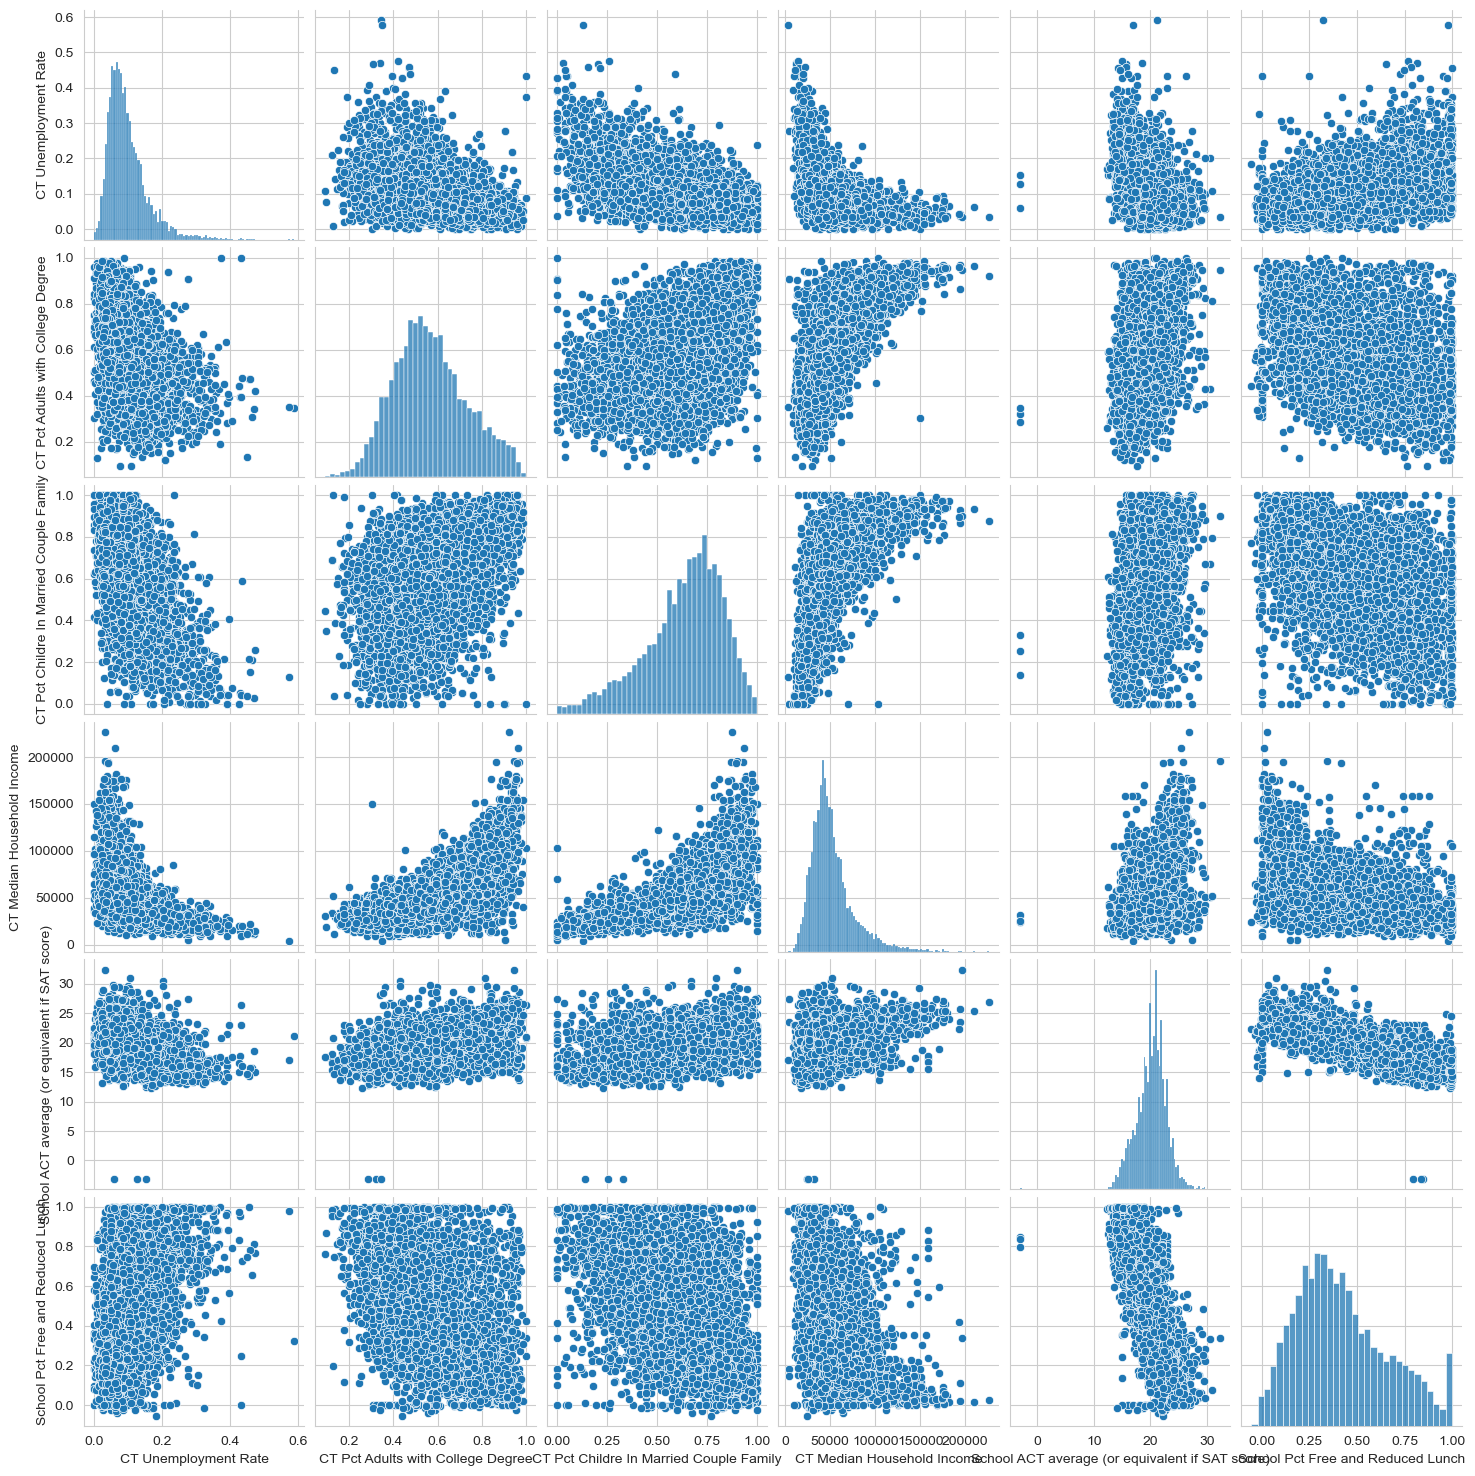

In [25]:
# Pair plot to explore relationships between the variables
sns.pairplot(
    edgap.drop(columns='NCESSCH School ID')
)
plt.show()

The ACT average shows a visible association with each of the other variables. The diagonal histograms show that the ACT average is roughly bell-shaped, while unemployment and income are skewed to the right. A few schools have implausible ACT averages well below 10, which we examine in the data quality section.

Next, add a regression line to every scatter plot and format the axis labels, to make the direction of each relationship easier to see.

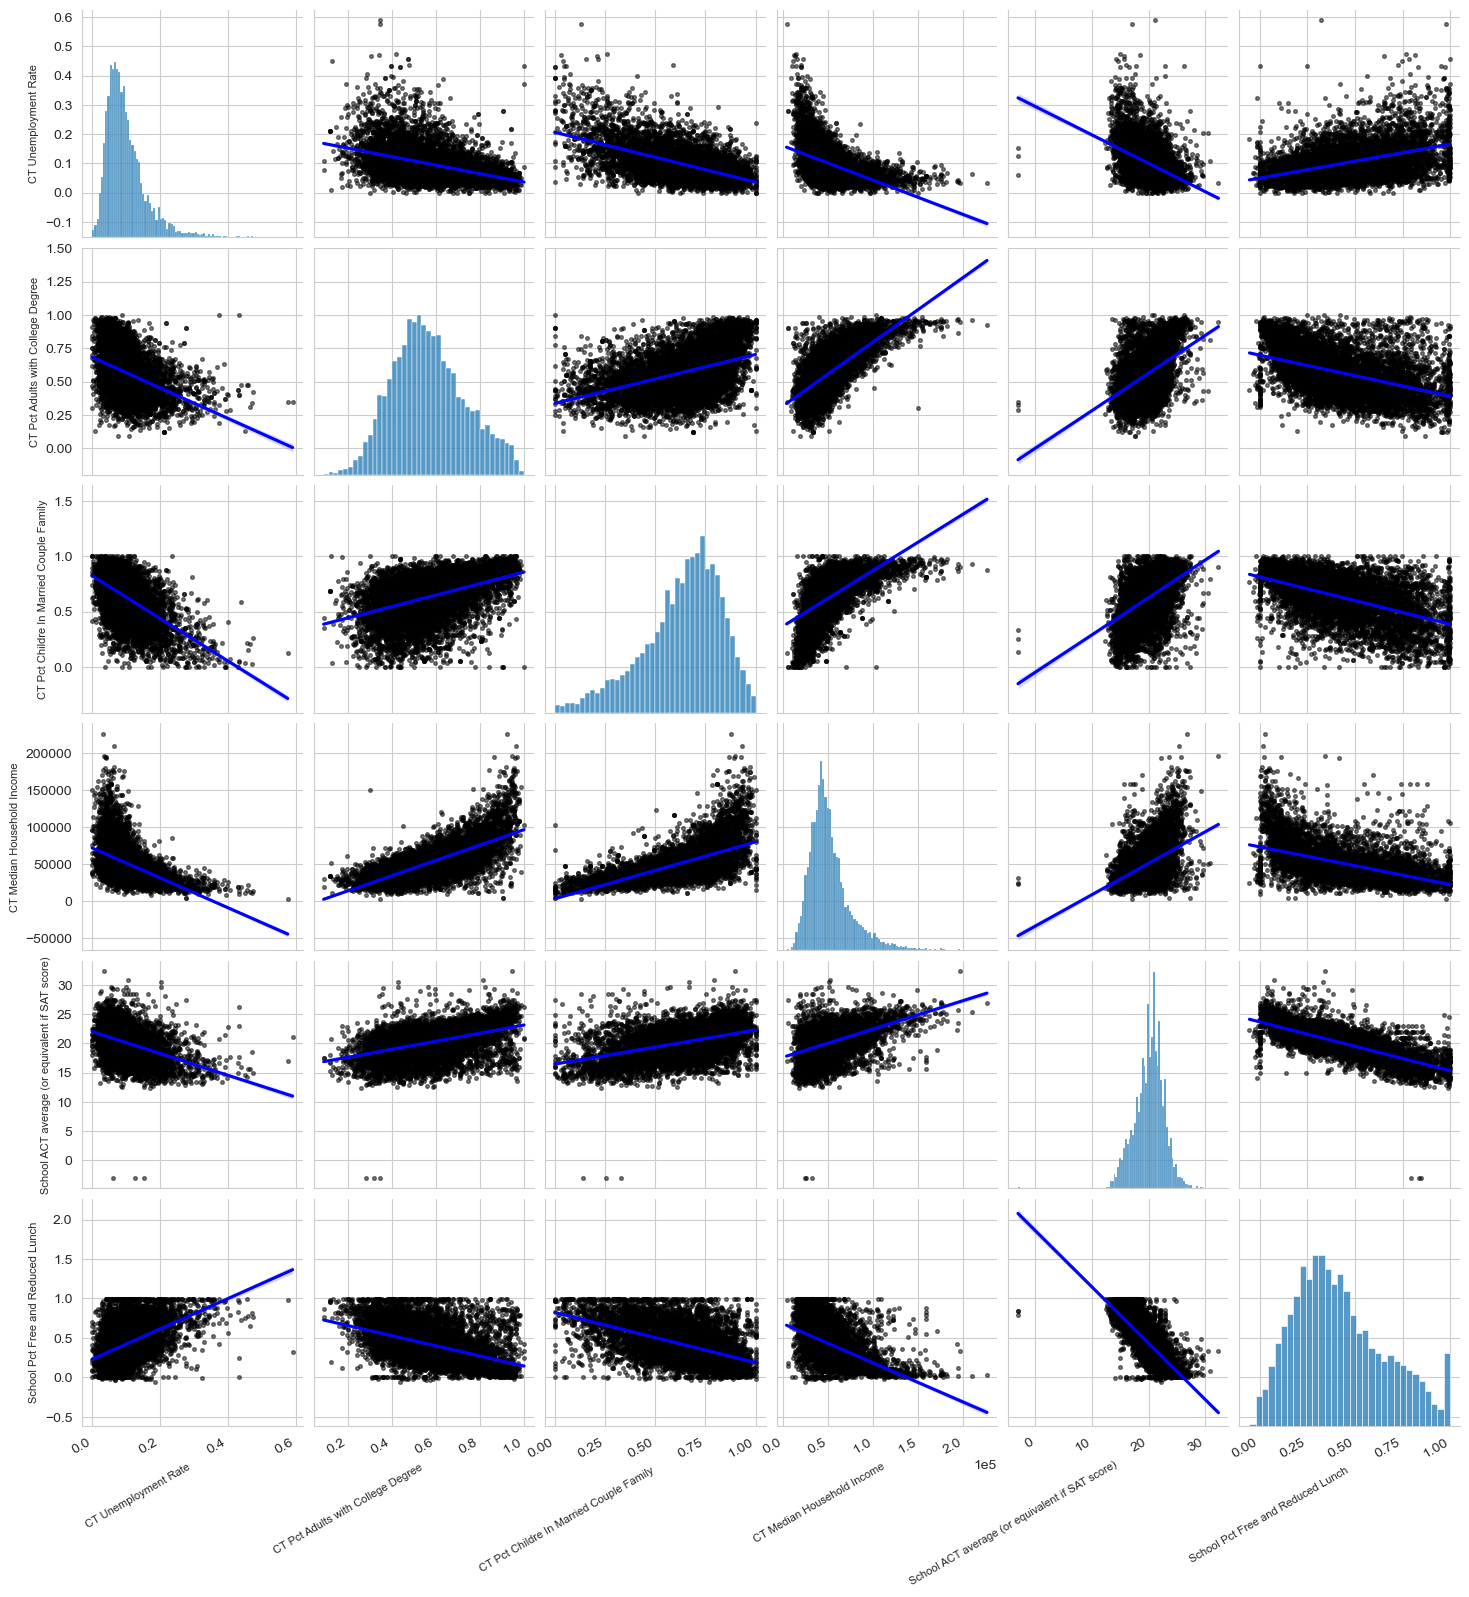

In [28]:
# Add regression lines and format the pair plot
fig = sns.pairplot(
    edgap.drop(columns='NCESSCH School ID'),
    kind="reg",
    plot_kws={
        "line_kws":{"color":"blue"},
        "scatter_kws":{"alpha":0.5,"color":"k","s":7},
    }
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style='sci',axis='x',scilimits=(0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation=30, ha='right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize=8) # Y-axis label size

   # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    
plt.show()

The regression lines show that the ACT average tends to fall as unemployment and the free/reduced lunch percentage rise, and tends to rise with the percentage of adults with a college degree, the percentage of children in married-couple families, and median household income. The socioeconomic variables are also related to each other: for example, income rises with the percentage of adults with a college degree.

Plot only the row of the pair plot that relates the ACT average to each of the other variables, which is the relationship we care about most.

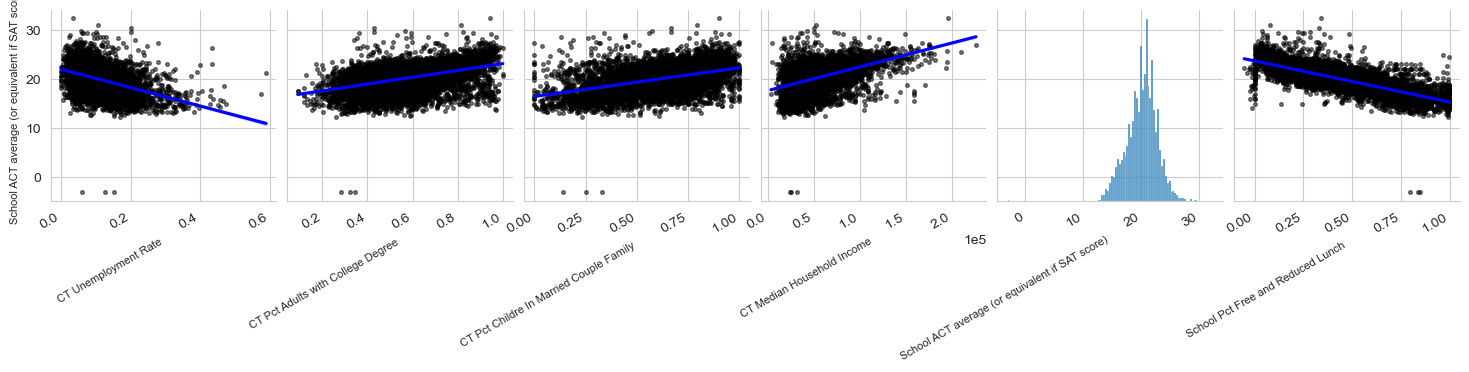

In [31]:
# Plot a single row
fig = sns.pairplot(
    edgap.drop(columns='NCESSCH School ID'),
    y_vars=['School ACT average (or equivalent if SAT score)'],
    kind="reg",
    plot_kws={
        "line_kws":{"color":"blue"},
        "scatter_kws":{"alpha":0.5,"color":"k","s":7},
    }
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style='sci',axis='x',scilimits=(0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation=30, ha='right') #x=axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize=8) # Y-axis label size

   # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    
plt.show()

The single row confirms the pattern: the ACT average has a negative relationship with unemployment and with the free/reduced lunch percentage, and a positive relationship with college degree, married-couple families, and income. The relationship with the lunch percentage looks the tightest. A few schools have ACT averages near -3, which is impossible because ACT scores range from 1 to 36.

- There appears to be a relationship between the socioeconomic variables and the ACT score.
- There are some out-of-range ACT and percent lunch values that will need to be dealt with.
- We should have confidence that it is worthwhile to spend time preparing the data for analysis.

### Data preparation
The school information data set contains many columns. We will only keep the year, school identity, location, and school type information.

Keep the columns SCHOOL_YEAR, NCESSCH, LSTATE, LZIP, SCH_TYPE_TEXT, LEVEL, CHARTER_TEXT

This code keeps only the seven columns we need from the NCES data and shows the first rows.

In [36]:
school_information = school_information[
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL', 'CHARTER_TEXT']
]
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,CHARTER_TEXT
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


The NCES data now has only the seven columns we need.

### Rename columns
Rename the columns SCHOOL_YEAR, NCESSCH, LSTATE, LZIP, SCH_TYPE_TEXT, LEVEL, CHARTER_TEXT to year, id, state, zip_code, school_type, school_level, charter

First, rename the EdGap columns to short, descriptive names, using `id` for the school identifier so it matches the NCES data.

In [40]:
edgap=edgap.rename(
    columns={
        "NCESSCH School ID":"id",
        "CT Unemployment Rate":"rate_unemployment",
        "CT Pct Adults with College Degree":"percent_college",
        "CT Pct Childre In Married Couple Family":"percent_married",
        "CT Median Household Income":"median_income",
        "School ACT average (or equivalent if SAT score)":"average_act",
        "School Pct Free and Reduced Lunch":"percent_lunch"
    }
)

In [41]:
school_information=school_information.rename(
    columns={
        "SCHOOL_YEAR":"year",
        "NCESSCH":"id",
        "LSTATE":"state",
        "LZIP":"zip_code",
        "SCH_TYPE_TEXT":"school_type",
        "LEVEL":"school_level",
        "CHARTER_TEXT":"charter"
    }
)

In [42]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


The EdGap columns now have short names, and the values are unchanged.

In [44]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,No
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,No
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,No
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,No
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,No


The NCES data now uses the same `id` name as the EdGap data, which lets us join the two data sets on this column.

### Join data frames
We want to join the DataFrames using the identity of the school as the key. The identity is given by the NCESSCH school identity. The value is an object in the EdGap data set and a float64 in the school information data set.

We will cast the id column in the school_information DataFrame as an object.

In [47]:
school_information['id'] = school_information['id'].astype('object')

In [48]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  object
 1   id            102181 non-null  object
 2   state         102183 non-null  object
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  object
 5   school_level  102179 non-null  object
 6   charter       102179 non-null  object
dtypes: object(7)
memory usage: 5.5+ MB


The `id` column in the NCES data is now an `object`, the same type as in the EdGap data.

Join the data frames and call the result `df`. We use a left join with the EdGap data on the left, so every EdGap school is kept even if it has no match in the NCES data.

In [51]:
df=edgap.merge(
    school_information,
    how='left',
    on='id'
)

In [52]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


Each EdGap school now has its state, zip code, school type, school level, and charter status attached.

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   object 
 8   state              7898 non-null   object 
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   object 
 11  school_level       7898 non-null   object 
 12  charter            7898 non-null   object 
dtypes: float64(6), object(7)
memory usage: 811.2+ KB


The joined data has 7,986 rows and 13 columns, the same number of rows as the EdGap data, as expected for a left join. Only 7,898 schools have NCES information, so 88 EdGap schools did not match any school in the NCES file. Those schools have missing values in the NCES columns.

### Quality control: remove unnecessary parts of the data sets
There are natural bounds for the numerical variables in the data set. Check the minimum and maximum values in each column. We can use the describe() method to compute descriptive statistics.

In [57]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


Most variables are within their natural bounds. The ACT average has a minimum of about -3.07, and the lunch percentage has a minimum of about -0.05. Both are impossible: ACT scores range from 1 to 36, and a percentage cannot be negative. The mean ACT average is about 20.2 and the mean lunch share is about 42%.

Use the minimum and maximum of each numerical column to check the bounds more directly.

In [60]:
df.select_dtypes(include=['number']).agg(['min','max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


The unemployment rate, college degree share, and married-couple share are between 0 and 1, as they should be. Median income ranges from about 3,600 to about 226,000 USD, which is wide but plausible for census tracts. The negative ACT and lunch values are the only values outside their natural bounds.

Set the out-of-range values to missing so they are not treated as real measurements: ACT averages below 1 and negative lunch percentages.

In [63]:
# Set out-of-range values to NaN using np.nan
df.loc[df['percent_lunch']<0,'percent_lunch']= np.nan
df.loc[df['average_act']<1,'average_act']= np.nan

The impossible values are now missing.

Check the types, levels, and charter status of the schools, to decide which schools belong in the analysis.

In [66]:
print(df['school_type'].value_counts())
print(df['school_level'].value_counts())
print(df['charter'].value_counts())

school_type
Regular School                 7885
Alternative School               10
Special Education School          2
Career and Technical School       1
Name: count, dtype: int64
school_level
High            7230
Other            631
Not reported      35
Elementary         2
Name: count, dtype: int64
charter
No                7329
Yes                352
Not applicable     217
Name: count, dtype: int64


Almost all schools (7,885 of 7,898) are regular schools. By level, 7,230 are high schools, 631 are "Other", 35 are "Not reported", and 2 are elementary schools. For charter status, 7,329 are not charter schools, 352 are charter schools, and 217 are "Not applicable". Charter schools are a small share of the sample.

We are interested in high schools, so keep only schools whose level is "High". This also removes the 88 schools that had no NCES information, because their level is missing.

In [69]:
# Keep only the high schools
df=df.loc[df['school_level']=='High']

In [70]:
# Check for any duplicated rows
df.duplicated().sum()

0

The count is 0, so there are no duplicated rows.

### Identify missing values
How many values of each variables are missing?

In [73]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


Among the high schools, the missing values are in the socioeconomic variables: 12 for unemployment, 11 for college degree, 20 for married couples, 16 for median income, and 20 for the lunch percentage. Three schools are missing the ACT average (the impossible negative values we set to missing).

Express the missing values as a percentage of all high schools to judge how serious the problem is.

In [76]:
percent_missing = df.isna().mean().round(4) * 100
percent_missing.to_frame(name="Percent Missing Values")

,Percent Missing Values
id,0.00
rate_unemployment,0.17
percent_college,0.15
percent_married,0.28
median_income,0.22
average_act,0.04
percent_lunch,0.28
year,0.00
state,0.00
zip_code,0.00


No variable is missing more than 0.3% of its values, so missing data is a very small problem in this data set.

What states do we have data from?

In [79]:
df['state'].value_counts()

state
TX    913
OH    654
IL    564
PA    543
MI    498
NC    407
FL    404
GA    367
WI    351
NJ    341
MO    337
IN    321
NY    295
TN    265
WA    263
MA    253
KY    198
LA    194
WY     38
DE     24
Name: count, dtype: int64

Texas has the most schools (913), followed by Ohio (654), Illinois (564), Pennsylvania (543), and Michigan (498). Wyoming (38) and Delaware (24) have the fewest.

Count how many different states appear in the data.

In [82]:
df['state'].nunique()

20

The data come from only 20 states, far fewer than the 50 states in the country.

Plot the number of schools in each state on a map of the United States.

In [85]:
# Import libraries
import plotly.offline as po
import plotly.graph_objs as pg

In [86]:
# Draw the map. States that have no schools in the data are left blank.
layout = dict(
    geo={"scope":"usa"}, coloraxis_colorbar=dict(title="Number of Schools")
)
data = dict(
    type="choropleth",
    locations=df["state"].value_counts().index,
    locationmode="USA-states",
    z=df["state"].value_counts().values,
    coloraxis="coloraxis"
)

x=pg.Figure(data=[data],layout=layout)
po.iplot(x)

The map shows schools spread across the Midwest, Northeast, and South, with only two western states (Washington and Wyoming).

We are missing a large amount of USA data due to omission. This is not evident by examining NaN values in the data set.

We could obtain this information from public records, but we will not do that here. Because 30 states are absent, any conclusions apply only to the states in the data, and may not generalize to the whole country.

Drop the rows where the average ACT score is missing

In [90]:
df=df.dropna(subset=['average_act'])

The 3 schools without an ACT average are removed, leaving 7,227 schools.

In [92]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


The ACT average no longer has missing values. The remaining missing values are in the predictor variables, which we handle next.

### Data imputation
Define the predictor variables to be rate_unemployment, percent_college, percent_married, median_income, percent_lunch, state, and charter

In [95]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]

Use the iterative imputer to replace missing values in the columns corresponding to predictor variables in the analysis

In [97]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [98]:
imputer = IterativeImputer()

Fit the imputer using the numerical predictor variables (this can include dummies for categorical variables)

In [100]:
# Define the columns you want to use in the imputation process
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()
print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


Five predictors are numerical: unemployment rate, college degree share, married-couple share, median income, and lunch percentage. The other two predictors, state and charter status, are categories and have no missing values.

In [102]:
# Fit the imputer
imputer.fit(df.loc[:,numerical_predictors])

IterativeImputer()

The imputer has learned how the numerical predictors relate to each other.

Replace the missing values in the numerical predictors with the imputed values.

In [105]:
df.loc[:,numerical_predictors] = imputer.transform(df.loc[:,numerical_predictors])

In [106]:
# Check for missing values
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


Every column now has 0 missing values, so the data set is complete and ready for analysis.

### Create derived variables
The charter question compares charter and non-charter schools, and regression models need a numerical predictor. This code derives an indicator variable, `is_charter`, from the `charter` column: 1 for charter schools, 0 for non-charter schools, and missing for schools whose charter status is "Not applicable", because those belong to neither group. It then counts the schools in each combination of `charter` and `is_charter` to check the result.

In [109]:
df['is_charter'] = df['charter'].map({'Yes': 1, 'No': 0})
df[['charter', 'is_charter']].value_counts(dropna=False)

charter         is_charter
No              0.0           6858
Not applicable  NaN            199
Yes             1.0            170
Name: count, dtype: int64

The indicator is created: 6,858 non-charter schools get 0, 170 charter schools get 1, and the 199 schools with "Not applicable" status are missing, as intended. The column is stored as 0.0 and 1.0 because it contains missing values. These are the same group sizes used in the comparison in Section 3. The standardized predictors created in the Scaling section of Section 4 are also derived variables.

### Export the clean data set

In [112]:
df.to_csv(
    '../data/education_clean.csv',
    encoding='utf-8-sig',
    index=False
)

The clean data set is saved as `education_clean.csv`.

## 2. Exploratory Data Analysis

### Import libraries
This code imports the libraries for this section. `matplotlib` and `seaborn` are used for plots now; the preprocessing, `statsmodels`, and `scikit-learn` metric imports are for the modeling that follows the exploration.

In [116]:
# Import numpy, pandas, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library liabrary built on matplotlib
import seaborn as sns

# Set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

### Load clean data

In [118]:
df = pd.read_csv("../data/education_clean.csv")

In [119]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,is_charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,1.0
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,0.0
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,0.0
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,0.0
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,0.0


The data has the same 13 columns as before: the school ID, the five socioeconomic variables, the ACT average, and the year, state, zip code, school type, school level, and charter status. Reading the CSV turns the ID and zip code into plain numbers. Zip codes that start with 0 may lose the leading zero, which does not matter here because we do not use zip codes in the analysis.

### Examine distributions and relationships

Plot the correlation matrix of the numerical variables in the training data to explore relationships between the variables.

Each cell of the heatmap shows the correlation between two variables, from -1 (perfect negative) to 1 (perfect positive).

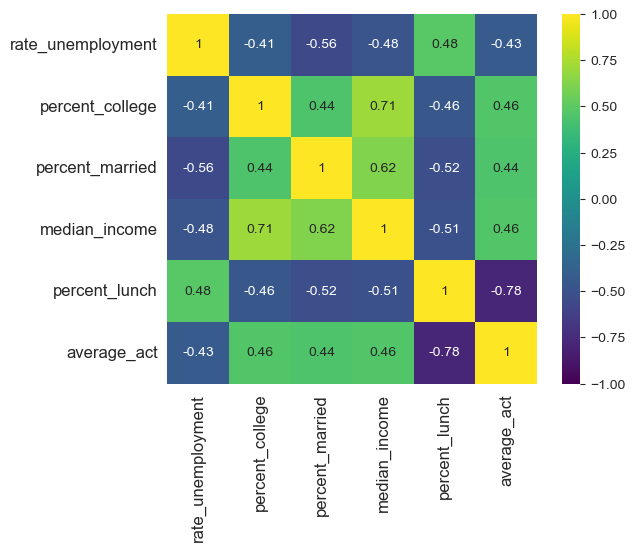

In [123]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]
numerical_predictors = df[predictor_variables].select_dtypes(include='number').columns.to_list()

corr_matrix = df[numerical_predictors +["average_act"]].corr()

sns.heatmap(
    corr_matrix, vmax= 1, vmin = -1, square = True, annot = True, cmap = "viridis"
)

plt.tick_params(labelsize=12)

plt.show()

The free/reduced lunch percentage has the strongest relationship with the ACT average (correlation -0.78): schools with more students on subsidized lunch tend to have lower ACT averages. College degree share (0.46), median income (0.46), and married-couple share (0.44) are moderately positively related to the ACT average, and unemployment is moderately negatively related (-0.43).

The predictors are also correlated with each other. The strongest are college degree share with median income (0.71) and median income with married-couple share (0.62). Because the predictors overlap, we should be careful when interpreting the effect of any single predictor in a regression model.

Make pair plots to explore relationships between the variables. The pair plots below use a separate color for each charter status and format the axis labels.

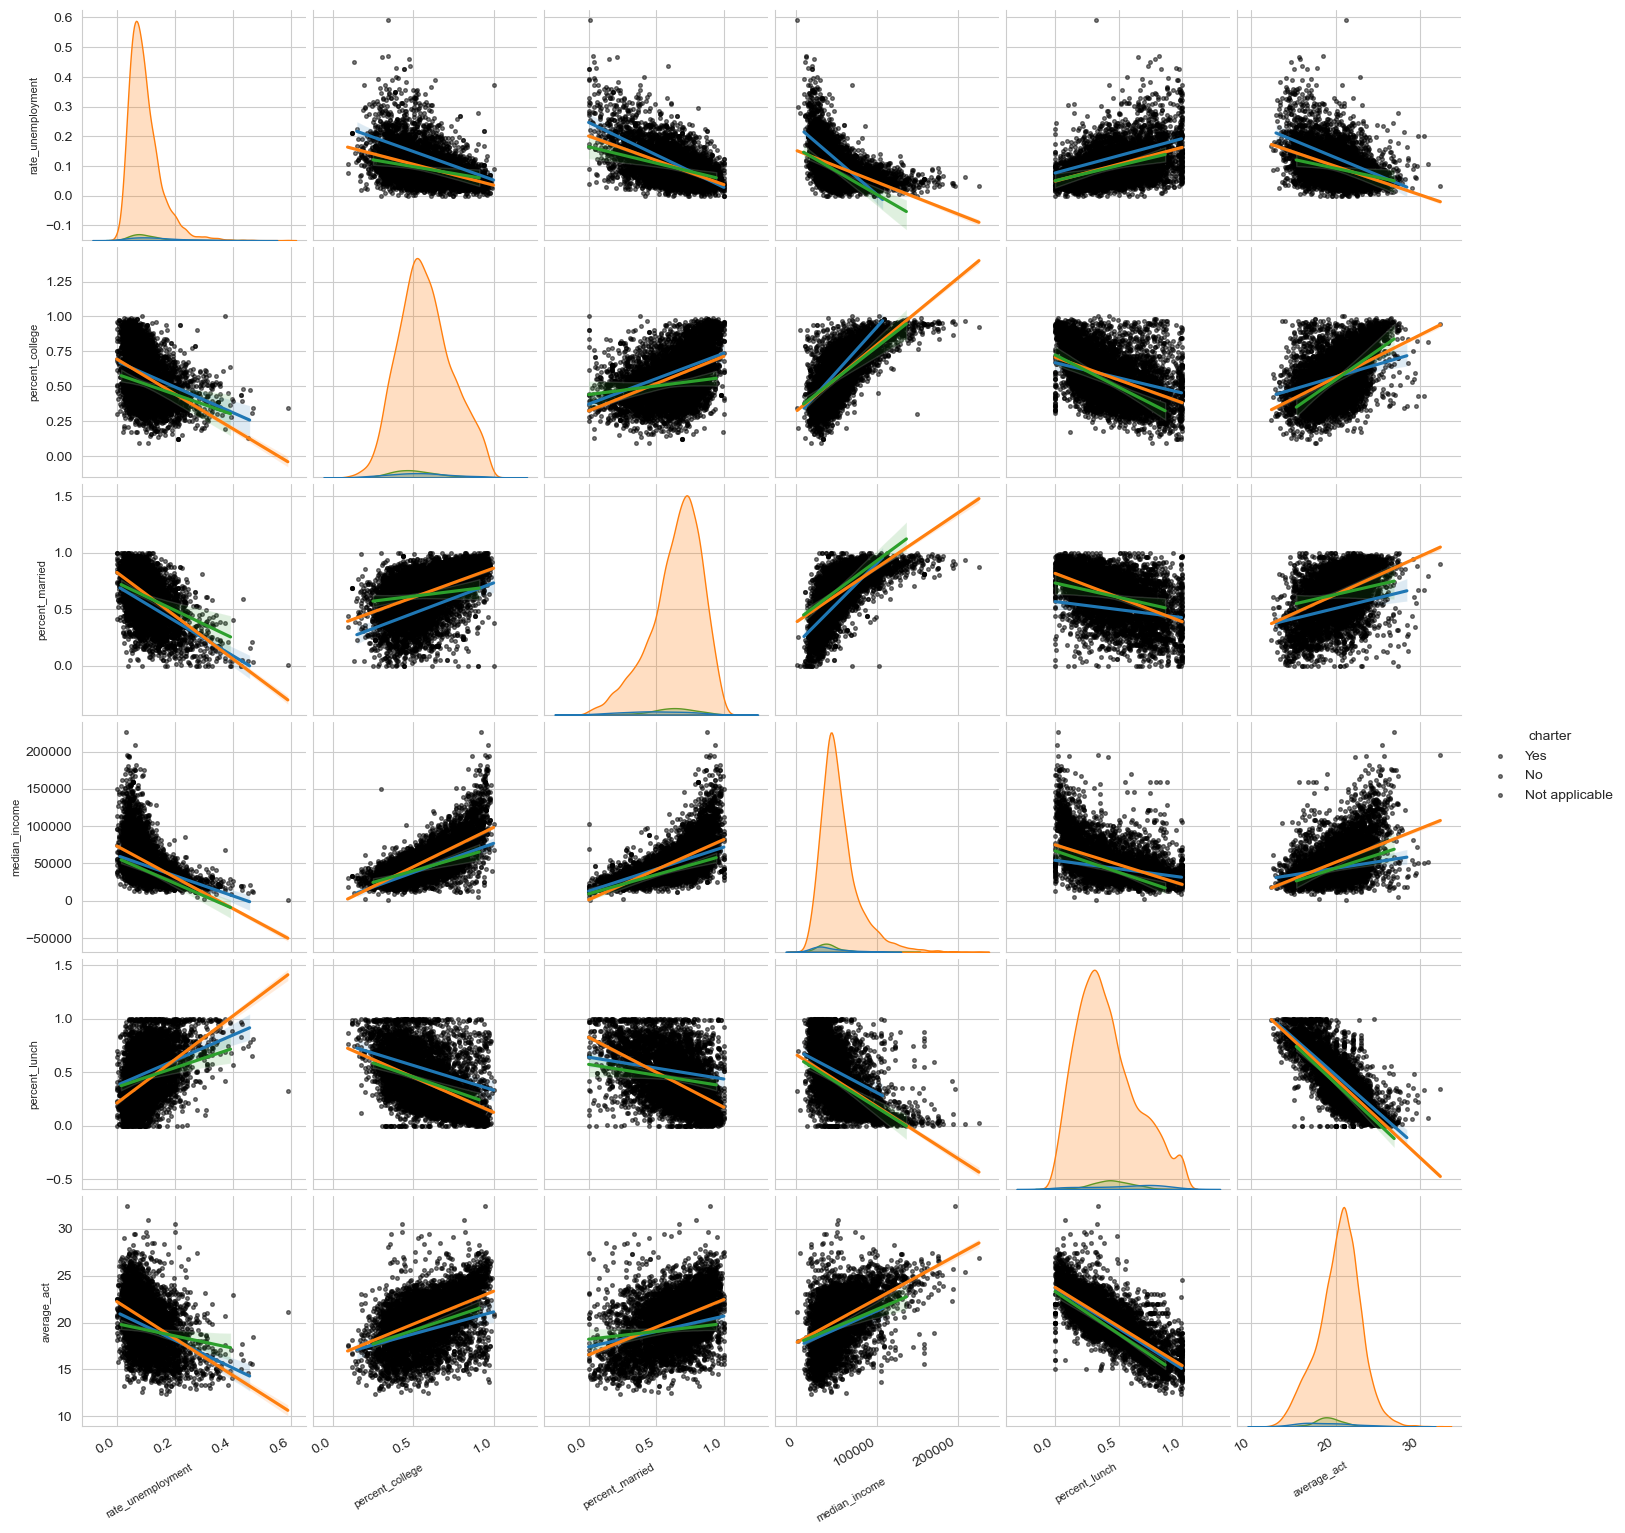

In [126]:
fig = sns.pairplot(
    data=df,
    vars=numerical_predictors + ['average_act'],
    hue='charter',
    kind="reg",
    plot_kws={
        "scatter_kws":{"alpha": 0.5, "color":"k", "s": 7},
    }
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
        ax.ticklabel_format(style='sci',axis='x',scilimits=(0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation=30, ha='right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize=8) # Y-axis label size

   # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.show()

The cleaned data show the same relationships as before, and the impossible ACT values near -3 are gone. For each of the three charter groups, the ACT average falls with unemployment and lunch percentage and rises with college degree share, married-couple share, and income. The slopes differ somewhat between groups, but charter schools and "Not applicable" schools are far fewer than non-charter schools, so their lines are less certain. The regression lines also extend past possible values (for example, negative income), which is only an artifact of drawing a straight line.

#### Identify outliers

We can use the interquartile range to identify outliers. This is also evident in boxplots of the data. Median income is on a very different scale than the other predictors, so we will make two plots to explore the data.

The first plot shows the four predictors that are proportions between 0 and 1.

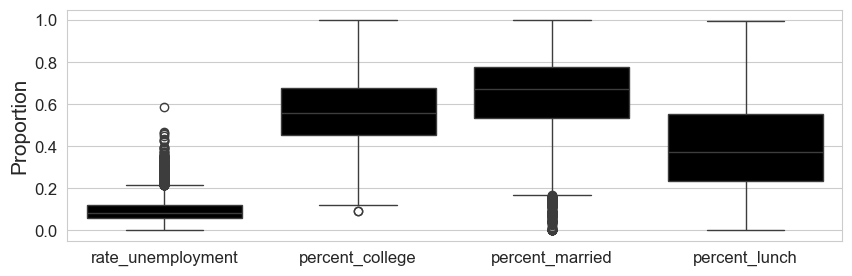

In [131]:
plt.figure(figsize=(10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data=df[fractions], color='k')
plt.ylabel('Proportion', fontsize=15)
plt.tick_params(labelsize=12)
               
plt.show()

Unemployment is skewed to the right, with many schools in communities with unemployment above about 0.2. The married-couple share is skewed to the left, with many schools below about 0.17. The college degree share has one low outlier near 0.09, and the lunch percentage has no outliers. These extreme values look like real communities (for example, areas with very high unemployment) rather than errors, so there is no reason to remove them.

The second plot shows median income, which is on a dollar scale.

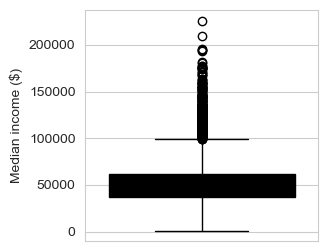

In [134]:
plt.figure(figsize=(3,3))
sns.boxplot(data=df, y='median_income', color='k')
plt.ylabel('Median income ($)')

plt.show()

Median income is skewed to the right: most schools are in tracts with a median income under about 100,000 USD, and many wealthier tracts appear as outliers, with the highest above 200,000 USD. These are plausible high-income communities, so they are kept in the data.

## 3. Research question and initial analysis

### Research question
**Do charter high schools have lower average ACT/SAT scores than non-charter public high schools, and how much of any difference is explained by the socioeconomic characteristics of the communities they serve?**

*Why it matters:* Charter schools are publicly funded schools that operate independently of the traditional district system. If they score lower, that could mean they serve students who face more disadvantages, or that something about the schools themselves matters. Separating the two is a question about equality of educational opportunity.

*Hypothesis:* Charter high schools have a lower average ACT score than non-charter high schools, but most of that gap is explained by the lower socioeconomic status of the communities where they are located. Once we account for the five socioeconomic variables, the remaining difference should be small.

*Data:* The ACT scores and the socioeconomic variables come from the EdGap data, and the charter status comes from the `charter` column of the NCES school information data, which is joined to the EdGap data above. No additional data set is used.

*Approach:* This is mainly a descriptive and diagnostic analysis: first compare the two groups of schools, then estimate the charter difference with and without accounting for socioeconomic variables.

#### Select the schools to compare
Keep only schools that are clearly charter ("Yes") or non-charter ("No"). Schools with charter status "Not applicable" are left out because they belong to neither group. This code also creates an indicator column, `is_charter`, equal to 1 for charter schools and 0 otherwise, for use in the model later. It then counts the schools in each group.

In [139]:
df_charter = df.loc[df['charter'].isin(['Yes', 'No'])].copy()
df_charter['charter'].value_counts()

charter
No     6858
Yes     170
Name: count, dtype: int64

The comparison uses 7,028 high schools: 6,858 non-charter and only 170 charter schools (about 2.4%). The 199 schools with "Not applicable" status are excluded. The charter group is small, so estimates for it will be less precise than for non-charter schools.

#### Compare average ACT scores
Summarize the distribution of the average ACT score for each group of schools.

In [142]:
df_charter.groupby('charter')['average_act'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
charter,,,,,,,,
No,6858.0,20.36,2.50,12.36,18.90,20.60,22.00,32.36
Yes,170.0,19.02,3.14,12.90,16.59,18.89,21.12,28.40


Charter schools have a lower average ACT score. The mean is 19.02 for charter schools versus 20.36 for non-charter schools, a raw gap of about 1.3 points, and the median gap is even larger (18.89 versus 20.60). Charter schools are also more spread out (standard deviation 3.14 versus 2.50). The distributions still overlap a great deal: the charter schools' middle half runs from about 16.6 to 21.1, while the non-charter schools' runs from about 18.9 to 22.0.

Show the same comparison as a boxplot.

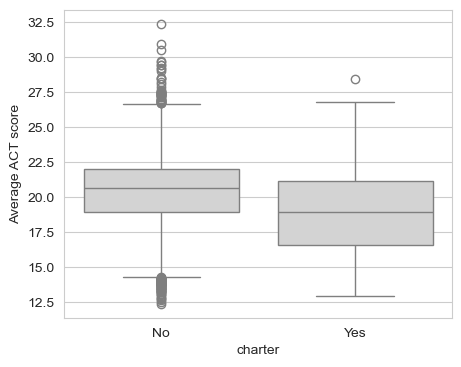

In [145]:
plt.figure(figsize=(5, 4))
sns.boxplot(data=df_charter, x='charter', y='average_act', order=['No', 'Yes'], color='lightgray')
plt.ylabel('Average ACT score')

plt.show()

The boxplot shows the same pattern. The charter box sits lower and is taller, and the whiskers of the two groups overlap. Many charter schools score as high as typical non-charter schools, even though the average is lower.

#### Compare the communities the schools serve
If charter schools tend to be in more disadvantaged communities, that could explain part of their lower scores. This code compares the average of each socioeconomic variable for the two groups.

In [148]:
socioeconomic_variables = ['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']
df_charter.groupby('charter')[socioeconomic_variables].mean().round(3).T

charter,No,Yes
rate_unemployment,0.095,0.139
percent_college,0.575,0.551
percent_married,0.645,0.492
median_income,53356.946,41810.166
percent_lunch,0.406,0.541


Charter schools are in communities with greater socioeconomic disadvantage on four of the five measures. Compared with non-charter schools, the census tracts of charter schools have higher unemployment (13.9% versus 9.5%), lower median household income (about 41,800 USD versus 53,400 USD), a smaller share of children in married-couple families (49% versus 65%), and a larger share of students on free or reduced-price lunch (54% versus 41%). The share of adults with a college degree is similar (55% versus 58%).

Show the distribution of each socioeconomic variable for the two groups.

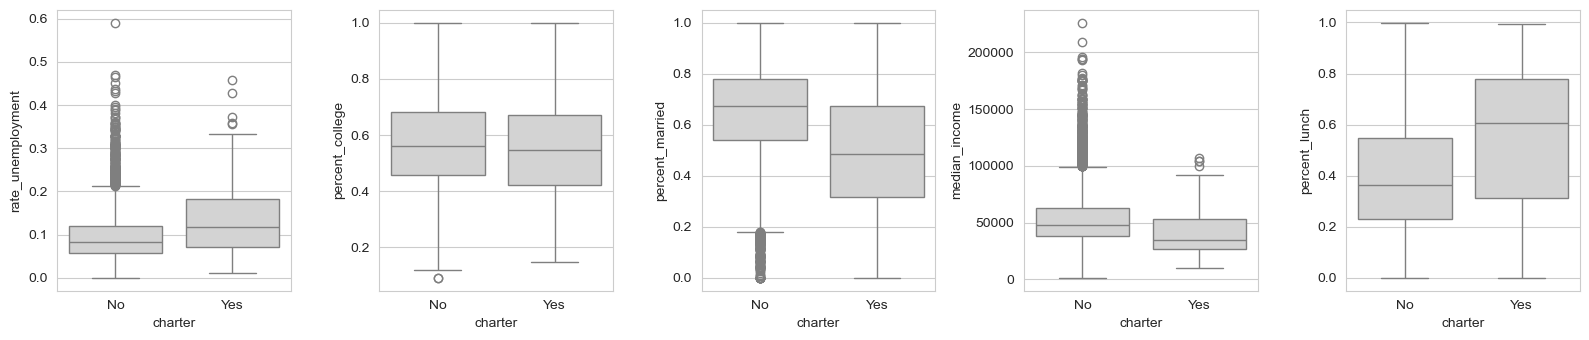

In [151]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for axis, variable in zip(axes, socioeconomic_variables):
    sns.boxplot(data=df_charter, x='charter', y=variable, order=['No', 'Yes'], color='lightgray', ax=axis)
plt.tight_layout()

plt.show()

The boxplots confirm that the differences are not driven by a few extreme schools. The whole distribution for charter schools is shifted toward higher unemployment, lower income, fewer married-couple families, and a higher lunch percentage, while the college degree distributions are close. This supports the hypothesis that charter schools in this data serve more disadvantaged communities.

#### Does the relationship between lunch percentage and ACT score differ by charter status?
The free/reduced lunch percentage had the strongest relationship with the ACT average (correlation -0.78). This plot draws a regression line for each group, with charter schools drawn on top. If the lines are about the same, charter and non-charter schools with similar lunch percentages have similar scores.

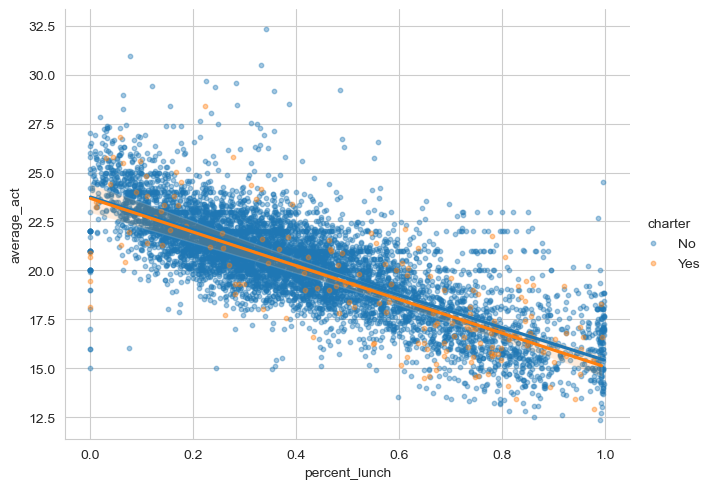

In [154]:
sns.lmplot(
    data=df_charter,
    x='percent_lunch',
    y='average_act',
    hue='charter',
    hue_order=['No', 'Yes'],
    scatter_kws={'alpha': 0.4, 's': 10},
    height=5,
    aspect=1.3,
)
plt.show()

The two regression lines nearly coincide. Charter schools are mostly found at higher lunch percentages (toward the right), where scores are lower for both groups, rather than sitting below the line for non-charter schools. At the same lunch percentage, charter and non-charter schools score about the same.

#### Preliminary statistical model
Estimate the charter difference using linear regression (ordinary least squares) with the average ACT score as the outcome. Three models show how the estimate changes as we account for more information:
1. No controls: only the charter indicator, which reproduces the raw gap.
2. Socioeconomic controls: adds the five socioeconomic variables.
3. Socioeconomic controls + state: also adds state, because states differ in school policies and in how many charter schools they have.

The table shows the coefficient on `is_charter` (the estimated difference in average ACT score for charter schools), its 95% confidence interval, its p-value, and the R-squared of each model.

In [157]:
socioeconomic_controls = ' + '.join(socioeconomic_variables)

charter_models = {
    'No controls': smf.ols('average_act ~ is_charter', data=df_charter).fit(),
    'Socioeconomic controls': smf.ols(f'average_act ~ is_charter + {socioeconomic_controls}', data=df_charter).fit(),
    'Socioeconomic controls + state': smf.ols(f'average_act ~ is_charter + {socioeconomic_controls} + C(state)', data=df_charter).fit(),
}

charter_results = pd.DataFrame(
    {
        'Charter coefficient': [model.params['is_charter'] for model in charter_models.values()],
        '95% CI lower': [model.conf_int().loc['is_charter', 0] for model in charter_models.values()],
        '95% CI upper': [model.conf_int().loc['is_charter', 1] for model in charter_models.values()],
        'p-value': [model.pvalues['is_charter'] for model in charter_models.values()],
        'R-squared': [model.rsquared for model in charter_models.values()],
    },
    index=charter_models.keys(),
).round(3)
charter_results

,Charter coefficient,95% CI lower,95% CI upper,p-value,R-squared
No controls,-1.341,-1.724,-0.958,0.000,0.007
Socioeconomic controls,-0.186,-0.423,0.051,0.124,0.628
Socioeconomic controls + state,-0.095,-0.318,0.127,0.401,0.678


Without controls, charter schools score 1.34 ACT points lower (95% confidence interval -1.72 to -0.96, p < 0.001), which matches the raw gap. Once the socioeconomic variables are included, the estimated difference shrinks to -0.19 points, and it is no longer statistically distinguishable from zero (interval -0.42 to 0.05, p = 0.12). Adding state brings it to -0.10 (interval -0.32 to 0.13, p = 0.40). The socioeconomic variables also explain far more of the variation in scores than charter status does: R-squared rises from 0.007 to 0.628 (0.678 with state).

In this data, most of the raw charter gap is therefore accounted for by the socioeconomic characteristics of the communities the schools serve, which is consistent with the hypothesis.

Next step is using the same two data sets, examine the charter difference separately by state, test whether the relationship between the lunch percentage and the ACT score differs for charter and non-charter schools (an interaction term), and check the model assumptions (for example, the residuals).

## 4. Modeling
### Single input models
Fit and assess a model that predicts the average ACT score from a single input variable. I use the free/reduced lunch share because the correlation matrix in Section 2 showed that it has the strongest relationship with the ACT average (correlation -0.78), and the pair plots showed an approximately straight-line trend.

#### Free/reduced lunch share
Plot the regression line and the scatter plot

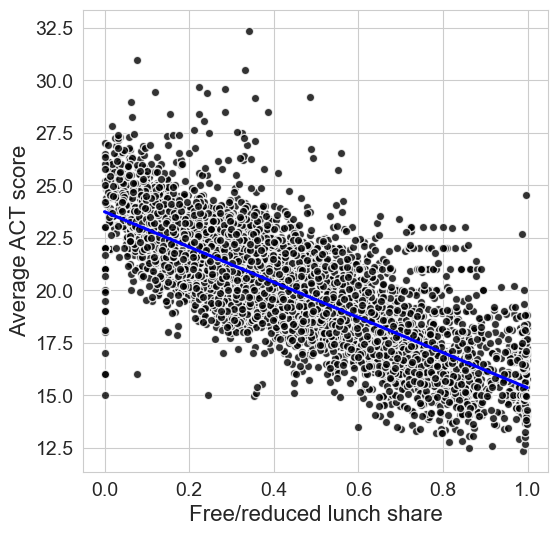

In [162]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='percent_lunch',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Free/reduced lunch share', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

The scatter plot shows a strong negative, roughly straight-line relationship: schools where a larger share of students are eligible for free or reduced-price lunch tend to have lower ACT averages. 

The blue line falls from about 24 at a share of 0 to about 15 at a share of 1. The points are packed much more closely around the line than they would be for a weaker predictor, although some schools score well above the line (up to about 32). The horizontal rows of points at whole-number scores may reflect rounding in the reported averages.

Fit the simple linear regression model

In [165]:
model_percent_lunch = smf.ols(formula='average_act ~ percent_lunch', data=df).fit()
print(model_percent_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.614
Model:                            OLS   Adj. R-squared:                  0.614
Method:                 Least Squares   F-statistic:                 1.149e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:37:16   Log-Likelihood:                -13461.
No. Observations:                7227   AIC:                         2.693e+04
Df Residuals:                    7225   BIC:                         2.694e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        23.7429      0.037    641.745

The free/reduced lunch share is a statistically significant predictor (t = -107.2, p < 0.001). The slope is -8.39 (95% confidence interval -8.54 to -8.24), so each 10 percentage point increase in the share of students eligible for free or reduced-price lunch is associated with a drop of about 0.84 points in the school's average ACT score. The intercept of 23.74 is the predicted ACT average for a school where no students are eligible. The R-squared is 0.614. The skewness (0.58) and kurtosis (5.8) show that the residuals are skewed to the right and have heavy tails, which we look at in the residual plot below.

#### Numerical assessment of fit accuracy
Compute the R-squared

In [168]:
model_percent_lunch.rsquared

0.6139194495900648

The R-squared is 0.614: the free/reduced lunch share alone explains about 61% of the variation in the average ACT score, so about 39% is left unexplained.

Compute the RMSE

In [171]:
y_hat = model_percent_lunch.predict()

In [172]:
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

1.559

The root mean squared error (RMSE) is 1.56 ACT points, a typical prediction error. The standard deviation of the ACT average itself is about 2.5 points, so using the lunch share reduces the typical error by about 38%.

Compute the mean absolute error

In [175]:
mean_absolute_error(df['average_act'], y_hat)

1.1689939374388358

The mean absolute error (MAE) is 1.17, so on average the predictions are off by about 1.17 ACT points.

Use a residual plot for graphical assessment of model fit

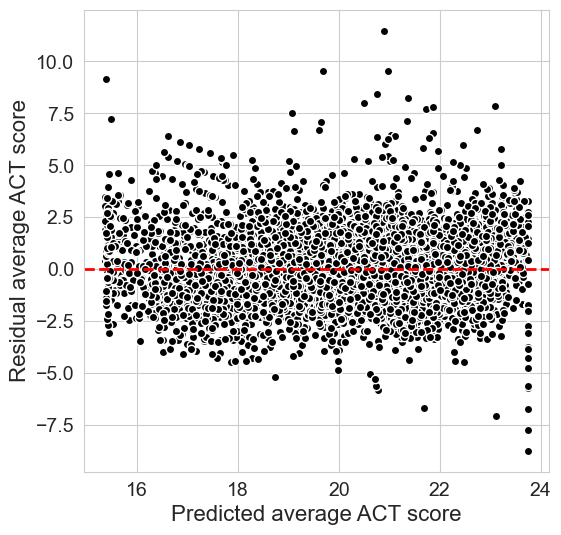

In [178]:
plt.figure(figsize=(6, 6))

plt.plot(y_hat, model_percent_lunch.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

The residuals are centered on zero and their spread is about the same at every predicted score. There is no funnel shape and no curve, so a straight line is a reasonable model for this relationship. A few schools have large positive residuals (they score up to 11 points higher than predicted), and a few schools at the highest predicted scores score 7 to 9 points lower than predicted. These are the heavy tails and skewness seen in the model summary.

The pair plots suggested a straight-line relationship. Plot the linear fit (blue) together with a quadratic curve (orange) to check whether the relationship is curved.

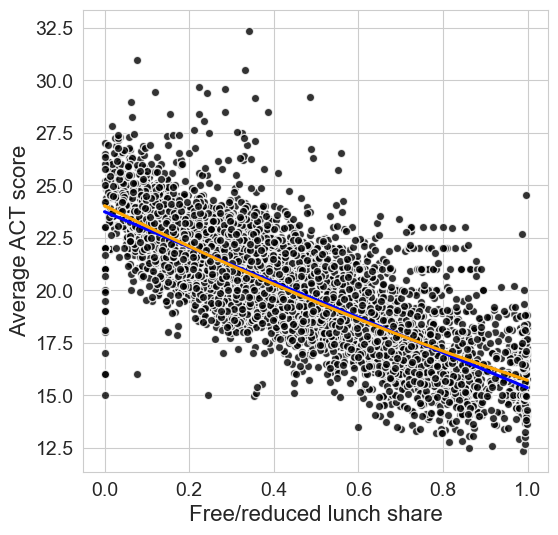

In [181]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='percent_lunch',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data=df,
            x='percent_lunch',
            y='average_act',
            order=2,
            color='orange',
            ci=False,
            scatter=False)

# Add axis labels
plt.xlabel('Free/reduced lunch share', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

The quadratic curve is almost on top of the straight line (blue). It sits slightly above the line at both ends and slightly below it in the middle, so any curvature is very small.

Fit a quadratic linear regression model

In [184]:
model_percent_lunch2 = smf.ols(
    formula='average_act ~ percent_lunch + I(percent_lunch**2)',
    data=df).fit()
print(model_percent_lunch2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.616
Model:                            OLS   Adj. R-squared:                  0.616
Method:                 Least Squares   F-statistic:                     5788.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:37:17   Log-Likelihood:                -13444.
No. Observations:                7227   AIC:                         2.689e+04
Df Residuals:                    7224   BIC:                         2.692e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                24.03

The quadratic model has an R-squared of 0.616, only slightly above the 0.614 of the linear model. The coefficient on the squared term is positive (1.70, t = 5.9), which means the decline in the ACT average flattens a little at high lunch shares. The larger condition number (24.7) is expected, because the lunch share and its square are strongly related.

Assess the model significance

In [187]:
model_percent_lunch2.pvalues

Intercept                 0.000000e+00
percent_lunch            1.867174e-246
I(percent_lunch ** 2)     4.256607e-09
dtype: float64

All p-values are very small (about 1.9e-246 for the lunch share and 4.3e-9 for its square), so both terms are statistically significant.

Use an ANOVA to test whether the quadratic model fits significantly better than the linear model.

In [190]:
anova_lm(model_percent_lunch, model_percent_lunch2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,17553.938543,0.0,NaN,NaN,NaN
1,7224.0,17470.292930,1.0,83.645613,34.587623,4.256607e-09


The F-test is significant (F = 34.6, p = 4.3e-9), so the quadratic model fits statistically better than the linear model. With about 7,200 schools even small improvements are significant, so we also need to check whether the improvement is large enough to matter.

Assess the model accuracy

In [193]:
# Compute the mean absolute error
mean_absolute_error(df['average_act'], model_percent_lunch2.predict())

1.1651018457233153

The mean absolute error of the quadratic model is 1.165.

Compute the mean absolute error of the linear model for comparison.

In [196]:
mean_absolute_error(df['average_act'], model_percent_lunch.predict())

1.1689939374388358

The linear model has an MAE of 1.169, only 0.004 ACT points worse than the quadratic model (about 0.3%). The curvature is statistically significant but practically negligible, so a straight line is an adequate description of the relationship between the free/reduced lunch share and the ACT score.

### Multiple linear regression
Fit the multiple linear regression model using all socioeconomic variables as predictors

In [199]:
model = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch',
    data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:37:18   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6972      0.13

Together, the five predictors explain 62.8% of the variation in the average ACT score (R-squared 0.628), compared with 61.4% for the free/reduced lunch share alone, so the other four predictors add only about 1.4 percentage points. Holding the other predictors fixed:
- Each 10 percentage point increase in the free/reduced lunch share lowers the ACT average by about 0.76 points (coefficient -7.60, t = -78.5), by far the strongest effect.
- Each 10 percentage point increase in the share of adults with a college degree raises it by about 0.17 points (coefficient 1.74), and each 10 point increase in unemployment lowers it by about 0.23 points (coefficient -2.27). Both are significant.
- The married-couple share (p = 0.58) and median income (p = 0.92) are not significant once the other predictors are included. Median income is strongly correlated with the college degree share (0.71) and the married-couple share (0.62), so these predictors overlap and add little new information once the others are in the model.

The large condition number (1.34e6) points to the overlap between predictors and the large scale of income.

Use a residual plot for graphical assessment of model fit

In [202]:
y_hat = model.predict()

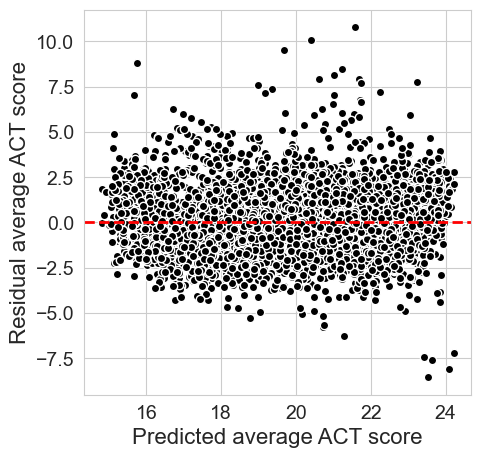

In [203]:
plt.figure(figsize=(5, 5))

plt.plot(y_hat, model.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

The residuals are centered on zero and their spread is roughly the same across predicted scores, without a clear curve. A linear model is therefore reasonable. There are some large positive residuals (schools scoring 5 to 10 points higher than predicted), and a few large negative ones at the highest predicted scores. This agrees with the skewness (0.58) and heavy tails (kurtosis 6.0) in the model summary.

Compute the mean absolute error

In [206]:
mean_absolute_error(df['average_act'], model.predict())

1.145330478885467

The MAE of the multiple regression model is 1.145, so predictions are off by about 1.1 ACT points on average. This is only about 2% smaller than the 1.169 of the model that uses the free/reduced lunch share alone, so the other four predictors add very little accuracy beyond the lunch share.

### Reduced model: fit a reduced model with the significant predictors

In [209]:
model_reduced = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df).fit()
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:37:18   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

The reduced model has the same R-squared (0.628) and the same adjusted R-squared as the full model, and all three predictors are significant. The coefficients are almost unchanged: -2.17 for unemployment, 1.71 for college degree share, and -7.59 for lunch share. The condition number falls from 1.34e6 to 25.9, so removing median income and the married-couple share removed the overlap between predictors.

Use a residual plot for graphical assessment of model fit

In [212]:
y_hat = model_reduced.predict()

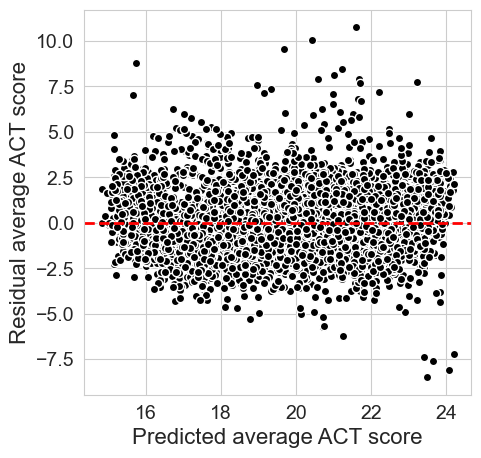

In [213]:
plt.figure(figsize=(5, 5))

plt.plot(y_hat, model_reduced.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

The residual plot is practically identical to that of the full model: centered on zero, roughly constant spread, and a few large positive residuals. Dropping the two predictors did not hurt the fit.

Compute the mean absolute error

In [216]:
mean_absolute_error(df['average_act'], model_reduced.predict())

1.1454832950346352

The MAE of the reduced model is 1.1455, essentially the same as the 1.1453 of the full model.

Compare the accuracy between full and reduced models

In [219]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
              'R_squared': [r2_full, r2_reduced]},
              index=['full model', 'reduced model']).round(4)

,Mean Absolute Error,R_squared
full model,1.1453,0.6280
reduced model,1.1455,0.6279


The full and reduced models are practically identical: the mean absolute error is 1.1453 versus 1.1455, and the R-squared is 0.6280 versus 0.6279. Median income and the married-couple share contribute nothing measurable, so the simpler three-predictor model is preferred.

Use an ANOVA to test the significance of difference between models

In [222]:
anova_lm(model_reduced, model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7221.0,16915.612457,2.0,1.006711,0.214874,0.806648


The ANOVA finds no significant difference between the reduced and full models (F = 0.21, p = 0.81). The extra two predictors do not significantly improve the fit, which supports using the reduced model.

### Scaling
Scale the predictor variables in the reduced model to have mean 0 and standard deviation 1 and add them to the data frame

In [225]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']
scaled_columns = [var + '_normalized' for var in predictor_variables]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']


The names of the new standardized columns are created by adding `_normalized` to the names of the three predictors in the reduced model. There is no other output.

In [227]:
scaler = StandardScaler().fit(df[predictor_variables])
df[scaled_columns] = scaler.transform(df[predictor_variables])

The scaler is fitted to the three predictors and the standardized columns are added to the data frame. There is no output.

In [229]:
# Check the mean and standard deviation of the transformed data
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


Each standardized column has a mean of 0 and a standard deviation of 1, so the scaling worked.

Fit the multiple linear regression model with the normalized predictors

In [232]:
model_normalized = smf.ols(
    formula='average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data=df).fit()
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:37:19   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

With all three predictors on the same scale, each coefficient is the change in the ACT average for a one standard deviation increase in the predictor, holding the others fixed. A one standard deviation increase in the free/reduced lunch share (about 23 percentage points) lowers the ACT average by 1.78 points, compared with an increase of 0.28 points for the college degree share and a decrease of 0.12 points for unemployment. The lunch share's effect is about 6 times that of the college degree share and about 14 times that of unemployment. The intercept of 20.30 is the average ACT score. The R-squared (0.628) is unchanged by the scaling.

Compare the accuracy between the original and normalized models

In [235]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
              'R_squared': [r2_normalized, r2_reduced]},
              index=['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R_squared
normalized model,1.1455,0.6279
reduced model,1.1455,0.6279


The normalized and reduced models have identical mean absolute error and R-squared. Scaling changes only the units of the coefficients, which makes them comparable, and does not change the fit or the predictions.

**Summary of the modeling.** The free/reduced lunch share alone explains about 61% of the variation in the average ACT score (MAE 1.17). A quadratic term is statistically significant but practically negligible. The five socioeconomic predictors together explain about 63%, and the reduced model with the lunch share, the college degree share, and the unemployment rate does just as well (R-squared 0.628, MAE 1.15). The free/reduced lunch share is by far the strongest predictor. The additional predictor, charter status, does not significantly improve the model (p = 0.14), and the estimated difference for charter schools after accounting for the community variables is about -0.18 ACT points.

### Adding the additional predictor: charter status
The additional predictor we chose is charter status, because the census variables describe a school's community but not the type of school. To test whether it improves the prediction of the ACT average, add the indicator `is_charter` to the reduced model. The comparison uses the charter and non-charter high schools (`df_charter`), because the indicator is missing for schools whose charter status is "Not applicable".

In [238]:
model_reduced_charter_subset = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df_charter).fit()

model_reduced_plus_charter = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch + is_charter',
    data=df_charter).fit()
print(model_reduced_plus_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2961.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:37:19   Log-Likelihood:                -13001.
No. Observations:                7028   AIC:                         2.601e+04
Df Residuals:                    7023   BIC:                         2.605e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6874      0.10

The reduced model plus charter status explains 62.8% of the variation in the average ACT score for the 7,028 charter and non-charter schools, and the coefficients of the other three predictors are close to those of the reduced model (-2.31 for unemployment, 1.67 for college degree share, -7.56 for lunch share). Holding the community variables fixed, charter schools score about 0.18 ACT points lower than non-charter schools, but this is not statistically significant (95% confidence interval -0.42 to 0.06, p = 0.14). The charter group is small (170 schools), so the interval does not rule out a small negative difference.

Use an ANOVA to test whether adding the charter indicator significantly improves the reduced model fitted to the same schools.

In [241]:
anova_lm(model_reduced_charter_subset, model_reduced_plus_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7024.0,16644.481603,0.0,NaN,NaN,NaN
1,7023.0,16639.270660,1.0,5.210944,2.199403,0.138109


The F-test agrees (F = 2.20, p = 0.14): adding the charter indicator does not significantly improve the reduced model. It lowers the residual sum of squares by only 5.2 out of about 16,640, or 0.03%. In this data, charter status therefore adds essentially no information about a school's average ACT score beyond the socioeconomic variables, which is consistent with the results of the comparison in Section 3.

## 5. Evaluation

The modeling section fitted a single-predictor model only for the free/reduced lunch share. This code computes the R-squared of a model with each of the five predictors alone, and also for lunch share plus median income, the reduced model, and the full model, so the predictors can be compared directly.

In [245]:
def r_squared(predictors):
    return smf.ols('average_act ~ ' + ' + '.join(predictors), data=df).fit().rsquared


r_squared_by_model = pd.Series({
    **{variable: r_squared([variable]) for variable in socioeconomic_variables},
    'percent_lunch + median_income': r_squared(['percent_lunch', 'median_income']),
    'Reduced model (unemployment, college, lunch)': r_squared(['rate_unemployment', 'percent_college', 'percent_lunch']),
    'Full model (all five predictors)': r_squared(socioeconomic_variables),
})
r_squared_by_model.round(3).to_frame(name='R-squared')

,R-squared
rate_unemployment,0.188
percent_college,0.210
percent_married,0.193
median_income,0.211
percent_lunch,0.614
percent_lunch + median_income,0.619
"Reduced model (unemployment, college, lunch)",0.628
Full model (all five predictors),0.628


The free/reduced lunch share explains 61.4% of the variation in the ACT average by itself. Each of the other four explains only 19% to 21% (unemployment 18.8%, married couples 19.3%, college degree 21.0%, median income 21.1%). Adding median income to the lunch share raises the R-squared only from 0.614 to 0.619, and the full model (0.628) is only slightly better than lunch share alone. Most of the explanatory power of the socioeconomic variables therefore comes from the lunch share.

The R-squared in the modeling section is computed on the same schools used to fit the model. This code uses 5-fold cross-validation, which repeatedly fits the reduced model on 80% of the schools and measures R-squared on the other 20%, to check how well it predicts new schools. It also shows the RMSE of the reduced model next to the standard deviation of the ACT average, which is the typical error of always guessing the mean.

In [248]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

reduced_predictors = ['rate_unemployment', 'percent_college', 'percent_lunch']

cross_validated_r_squared = cross_val_score(
    LinearRegression(), df[reduced_predictors], df['average_act'], cv=5, scoring='r2'
)

pd.Series({
    'R-squared on all schools': model_reduced.rsquared,
    'Mean cross-validated R-squared': cross_validated_r_squared.mean(),
    'RMSE of the reduced model (ACT points)': np.sqrt(mean_squared_error(df['average_act'], model_reduced.predict())),
    'Standard deviation of average ACT (ACT points)': df['average_act'].std(),
}).round(3).to_frame(name='Value')

,Value
R-squared on all schools,0.628
Mean cross-validated R-squared,0.600
RMSE of the reduced model (ACT points),1.530
Standard deviation of average ACT (ACT points),2.508


On schools held out of the fit, the reduced model explains about 60% of the variation (cross-validated R-squared 0.600), close to the 62.8% on all schools, so the model is not overfitted. The typical prediction error is about 1.5 ACT points, compared with 2.5 points without the predictors, so the predictors cut the typical error by about 39%. About 37% of the variation is not explained by these variables.

## 6. Results
### Summary of the models
This code compares the main models in one table: the number of schools, the R-squared (the share of the variation in the average ACT score that the model explains), and the mean absolute error (the average size of a prediction error, in ACT points).

In [251]:
models_to_compare = {
    'Free/reduced lunch share only': model_percent_lunch,
    'Five socioeconomic predictors': model,
    'Reduced model (unemployment, college degree, lunch share)': model_reduced,
}

model_comparison = pd.DataFrame(
    {
        'Number of schools': [int(fitted_model.nobs) for fitted_model in models_to_compare.values()],
        'R-squared': [fitted_model.rsquared for fitted_model in models_to_compare.values()],
        'Mean absolute error (ACT points)': [
            mean_absolute_error(df['average_act'], fitted_model.predict())
            for fitted_model in models_to_compare.values()
        ],
    },
    index=models_to_compare.keys(),
).round(3)
model_comparison

,Number of schools,R-squared,Mean absolute error (ACT points)
Free/reduced lunch share only,7227,0.614,1.169
Five socioeconomic predictors,7227,0.628,1.145
"Reduced model (unemployment, college degree, lunch share)",7227,0.628,1.145


All three models use the same 7,227 high schools. The free/reduced lunch share alone explains 61.4% of the variation in the average ACT score, and the five socioeconomic predictors together explain 62.8%, an improvement of only 1.4 percentage points. The reduced model with three predictors fits just as well as the full model (R-squared 0.628, mean absolute error 1.145), so unemployment, college degree share, and lunch share carry essentially all of the predictive information.

### Which predictors explain the most?
This plot shows the R-squared of each predictor by itself, along with the three larger models, so the predictors can be compared at a glance.

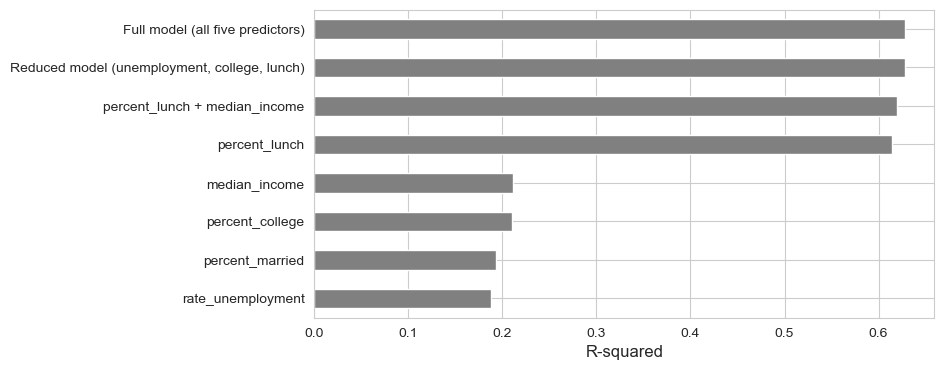

In [254]:
plt.figure(figsize=(8, 4))
r_squared_by_model.sort_values().plot.barh(color='gray')
plt.xlabel('R-squared', fontsize=12)
plt.show()

Each of unemployment, married-couple share, college degree share, and median income explains only 19% to 21% of the variation by itself, while the free/reduced lunch share explains 61%, about three times as much. Adding median income to the lunch share barely changes the result, and the full and reduced models are practically tied at the top.

### Do charter schools score differently once the community is taken into account?
This plot shows the estimated difference in the average ACT score for charter schools from the three charter models in Section 3. Each dot is the estimate and each line is its 95% confidence interval. A difference of zero (the dashed line) means no difference from non-charter schools.

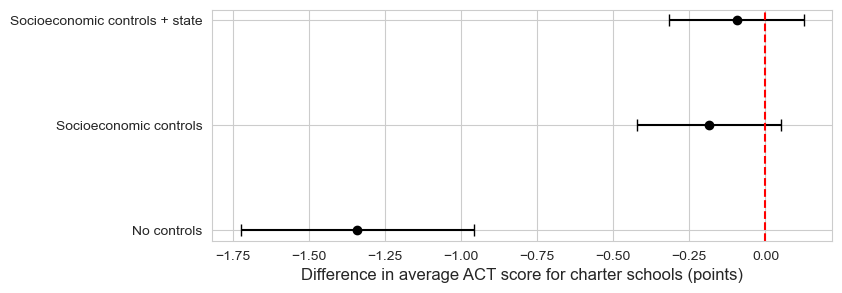

In [257]:
plt.figure(figsize=(8, 3))

estimate = charter_results['Charter coefficient']
error_below = estimate - charter_results['95% CI lower']
error_above = charter_results['95% CI upper'] - estimate
model_positions = range(len(charter_results))

plt.errorbar(estimate, model_positions, xerr=[error_below, error_above], fmt='o', color='black', capsize=4)
plt.axvline(0, color='r', linestyle='dashed')
plt.yticks(model_positions, charter_results.index)
plt.xlabel('Difference in average ACT score for charter schools (points)', fontsize=12)
plt.show()

Without controls, charter schools score about 1.3 points lower, and the interval is clearly below zero. Once the socioeconomic variables are included, the estimate moves close to zero (about -0.2 points), and with state added it is about -0.1 points. In both of these models the confidence interval includes zero, so the difference is no longer statistically distinguishable from no difference.

## 7. Conclusions
**Is school performance predicted by socioeconomic factors? Yes, to a large degree.**
- The five socioeconomic variables explain about 63% of the variation in the average ACT score between high schools (R-squared 0.628). On schools held out of the fit they still explain about 60% (cross-validated R-squared 0.600).
- A typical prediction is off by about 1.1 ACT points (mean absolute error), or 1.5 points by the RMSE, compared with a standard deviation of 2.5 points between schools. About 37% of the variation is left to other factors.

**The strongest predictor is the free/reduced lunch share.**
- By itself it explains 61% of the variation. Each 10 percentage point increase in the share of eligible students goes with a drop of about 0.84 ACT points. In standardized terms a one standard deviation increase lowers the ACT average by 1.78 points, compared with +0.28 for the college degree share and -0.12 for unemployment.
- Median income and the married-couple share add nothing significant once the other predictors are included (p = 0.92 and p = 0.58). The lunch share is likely a better measure of student poverty than the tract median income because it describes the students in the school themselves.

**The additional predictor, charter status, adds little once the community is taken into account.**
- Charter high schools score about 1.3 ACT points lower than non-charter high schools (19.0 versus 20.4). They also serve more disadvantaged communities: on average 54% of their students are eligible for free or reduced-price lunch versus 41%, the tract median income is about $41,800 versus $53,400, and unemployment is 13.9% versus 9.5%.
- After accounting for the socioeconomic variables, the estimated difference falls to about -0.2 points (95% confidence interval -0.42 to 0.05, p = 0.12), and to about -0.1 points when state is included. Adding charter status to the reduced model does not significantly improve it (p = 0.14). Most of the raw gap therefore reflects the communities that charter schools serve.

**Interpretation:**

Differences in average ACT scores between schools largely mirror the economic disadvantage of the students and communities they serve. This points to inequality of educational opportunity: schools serving more low-income students tend to have lower average scores, whatever their type.

**Limits of these conclusions:**

These are associations and not causal effects. The data cover only 20 states and one year (2016), the census variables describe tracts and not attendance areas, all values are school or tract averages, and only 170 charter schools are in the sample, so a small charter difference cannot be ruled out.

## 8. Tables and statistics reported in the report
The written report (Communicate the Results) quotes tables and summary statistics. This section reproduces each of them so that every number in the report can be traced to code. Some are already produced in earlier sections, and the cells below add the remaining ones.

### Table 1: descriptive statistics
This code computes the mean, standard deviation, minimum, and maximum of the average ACT score and the five socioeconomic variables, together with the correlation of each variable with the average ACT score.

In [262]:
table_variables = ['average_act'] + socioeconomic_variables

descriptive_statistics = df[table_variables].agg(['mean', 'std', 'min', 'max']).T
descriptive_statistics['correlation_with_act'] = df[table_variables].corr()['average_act']
descriptive_statistics.round(3)

,mean,std,min,max,correlation_with_act
average_act,20.299,2.508,12.363,32.363,1.000
rate_unemployment,0.096,0.057,0.000,0.590,-0.433
percent_college,0.573,0.165,0.091,1.000,0.458
percent_married,0.640,0.191,0.000,1.000,0.440
median_income,52745.418,24359.994,1091.668,226181.000,0.460
percent_lunch,0.411,0.234,0.000,0.999,-0.784


The mean of the average ACT score is 20.30 (standard deviation 2.51, range 12.36 to 32.36). The lunch share has the strongest correlation with the ACT average (-0.78), followed by median income (0.46), college degree share (0.46), married-couple share (0.44), and unemployment rate (-0.43). This is Table 1 of the report.

The correlations between the predictors quoted in the report are computed next.

In [265]:
predictor_correlations = df[socioeconomic_variables].corr()

pd.Series({
    'College degree share and median income': predictor_correlations.loc['percent_college', 'median_income'],
    'Median income and married-couple share': predictor_correlations.loc['median_income', 'percent_married'],
}).round(2).to_frame(name='Correlation')

,Correlation
College degree share and median income,0.71
Median income and married-couple share,0.62


College degree share and median income correlate at 0.71, and median income and married-couple share at 0.62. These are the largest correlations between predictors, which is why the predictors overlap.

### Table 2: model fit
This code computes the R-squared, mean absolute error (MAE), and root mean squared error (RMSE) of the five main models on all schools: lunch share alone, lunch share plus median income, lunch share plus its square, all five predictors, and the reduced model.

In [268]:
models_for_table_2 = {
    'Lunch share': model_percent_lunch,
    'Lunch share + median income': smf.ols('average_act ~ percent_lunch + median_income', data=df).fit(),
    'Lunch share + lunch share squared': model_percent_lunch2,
    'Five predictors (full)': model,
    'Unemployment, college, lunch (reduced)': model_reduced,
}

model_fit_table = pd.DataFrame(
    {
        'R-squared': [fitted.rsquared for fitted in models_for_table_2.values()],
        'MAE': [mean_absolute_error(df['average_act'], fitted.predict()) for fitted in models_for_table_2.values()],
        'RMSE': [np.sqrt(mean_squared_error(df['average_act'], fitted.predict())) for fitted in models_for_table_2.values()],
    },
    index=models_for_table_2.keys(),
).round(3)
model_fit_table

,R-squared,MAE,RMSE
Lunch share,0.614,1.169,1.559
Lunch share + median income,0.619,1.161,1.548
Lunch share + lunch share squared,0.616,1.165,1.555
Five predictors (full),0.628,1.145,1.530
"Unemployment, college, lunch (reduced)",0.628,1.145,1.530


This is Table 2 of the report. The lunch share alone has an R-squared of 0.614 (MAE 1.169, RMSE 1.559). Adding median income raises it to 0.619, and adding the squared lunch share raises it to 0.616. The five-predictor model and the reduced model both have an R-squared of 0.628, an MAE of 1.145, and an RMSE of 1.530, identical to three decimals.

#### Cross-validated R-squared by fold
This code computes the five-fold cross-validated R-squared of the reduced model and of the full model, showing each fold and the mean, to report the predictive performance on schools held out of the fit.

In [271]:
cross_validation_table = pd.DataFrame(
    {
        'Reduced model': cross_val_score(
            LinearRegression(), df[reduced_predictors], df['average_act'], cv=5, scoring='r2'),
        'Full model': cross_val_score(
            LinearRegression(), df[socioeconomic_variables], df['average_act'], cv=5, scoring='r2'),
    },
    index=[f'Fold {fold}' for fold in range(1, 6)],
)
cross_validation_table.loc['Mean'] = cross_validation_table.mean()
cross_validation_table.round(3)

,Reduced model,Full model
Fold 1,0.565,0.565
Fold 2,0.636,0.629
Fold 3,0.658,0.656
Fold 4,0.550,0.548
Fold 5,0.591,0.587
Mean,0.600,0.597


The cross-validated R-squared of the reduced model is 0.565, 0.636, 0.658, 0.550, and 0.591 in the five folds (mean 0.600), and the mean for the full model is 0.597. The score varies from about 0.55 to 0.66 between folds, and the two models are nearly identical in every fold.

### Table 3: reduced model coefficients
This code collects the coefficients of the reduced model with their 95% confidence intervals and p-values, together with the standardized coefficients from the model fitted to the standardized predictors, in one table.

In [274]:
standardized_coefficients = model_normalized.params.rename(index=lambda name: name.replace('_normalized', ''))
standardized_coefficients['Intercept'] = np.nan

reduced_model_table = pd.DataFrame(
    {
        'Coefficient': model_reduced.params,
        '95% CI lower': model_reduced.conf_int()[0],
        '95% CI upper': model_reduced.conf_int()[1],
        'Standardized coefficient': standardized_coefficients,
        'p-value': model_reduced.pvalues,
    }
).round(3)
reduced_model_table

,Coefficient,95% CI lower,95% CI upper,Standardized coefficient,p-value
Intercept,22.640,22.439,22.841,NaN,0.0
rate_unemployment,-2.168,-2.901,-1.436,-0.123,0.0
percent_college,1.714,1.465,1.963,0.283,0.0
percent_lunch,-7.586,-7.768,-7.405,-1.777,0.0


This is Table 3 of the report. The reduced model has an intercept of 22.640 and coefficients of -2.168 for unemployment rate (95% CI -2.901 to -1.436), 1.714 for college degree share (1.465 to 1.963), and -7.586 for lunch share (-7.768 to -7.405). The standardized coefficients are -0.123, 0.283, and -1.777. All p-values are below 0.001 (they show as 0.0 after rounding). The intercept has no standardized coefficient.

### Table 4: charter and non-charter schools
This code computes the mean and standard deviation of the ACT score and the socioeconomic variables for charter and non-charter schools.

In [277]:
charter_group_summary = (
    df_charter.groupby('charter')[['average_act'] + socioeconomic_variables]
    .agg(['mean', 'std'])
    .round(3)
    .T
)
charter_group_summary

charter                        No        Yes
average_act       mean     20.361     19.020
                  std       2.496      3.143
rate_unemployment mean      0.095      0.139
                  std       0.055      0.089
percent_college   mean      0.575      0.551
                  std       0.164      0.194
percent_married   mean      0.645      0.492
                  std       0.189      0.235
median_income     mean  53356.946  41810.166
                  std   24470.042  21352.457
percent_lunch     mean      0.406      0.541
                  std       0.234      0.282

Charter schools have a lower average ACT score (19.02 vs. 20.36) and a larger spread (SD 3.14 vs. 2.50). They also have a higher lunch share (0.541 vs. 0.406), lower median income (41,810 USD vs. 53,357 USD), higher unemployment (0.139 vs. 0.095), and a lower married-couple share (0.492 vs. 0.645). The college degree share is similar (0.551 vs. 0.575). This is Table 4 of the report.

### Table 5: charter difference estimates
This code puts the three charter models from Section 3 and the reduced model with the charter indicator from Section 4 in one table, with the estimated difference for charter schools, its 95% confidence interval, p-value, and the model R-squared.

In [280]:
reduced_plus_charter_row = pd.DataFrame(
    {
        'Charter coefficient': model_reduced_plus_charter.params['is_charter'],
        '95% CI lower': model_reduced_plus_charter.conf_int().loc['is_charter', 0],
        '95% CI upper': model_reduced_plus_charter.conf_int().loc['is_charter', 1],
        'p-value': model_reduced_plus_charter.pvalues['is_charter'],
        'R-squared': model_reduced_plus_charter.rsquared,
    },
    index=['Reduced model + is_charter'],
)
pd.concat([charter_results, reduced_plus_charter_row]).round(3)

,Charter coefficient,95% CI lower,95% CI upper,p-value,R-squared
No controls,-1.341,-1.724,-0.958,0.000,0.007
Socioeconomic controls,-0.186,-0.423,0.051,0.124,0.628
Socioeconomic controls + state,-0.095,-0.318,0.127,0.401,0.678
Reduced model + is_charter,-0.179,-0.415,0.058,0.138,0.628


This is Table 5 of the report. The estimated charter difference is -1.341 points with no controls (p < 0.001, shown as 0.000 after rounding), -0.186 with the socioeconomic controls (p = 0.124), -0.095 with state added (p = 0.401), and -0.179 when the charter indicator is added to the reduced model (p = 0.138). The R-squared values are 0.007, 0.628, 0.678, and 0.628.

### Charter schools by state
This code counts the charter schools in each state, to show how concentrated they are.

In [283]:
charter_schools_by_state = df_charter.groupby('state')['is_charter'].sum().astype(int).sort_values(ascending=False)
charter_schools_by_state.to_frame(name='Charter schools')

,Charter schools
state,
FL,31
MI,27
TX,27
PA,15
IL,10
MA,9
WI,8
NY,8
GA,6


Florida (31), Texas (27), and Michigan (27) have 85 of the 170 charter schools, followed by Pennsylvania (15) and Illinois (10). North Carolina, Washington, and Wyoming have no charter schools in the sample. Only 19 states appear because one of the 20 states has no schools with charter status "Yes" or "No".

### Other numbers quoted in the Discussion
This code computes the remaining quantities quoted in the Discussion of the report from the models above: the unexplained share of variance, the contribution of the lunch share, the ratios of the standardized effects, the small gains from median income and the quadratic term, the reduction of the charter gap after adjustment, and the condition numbers.

In [286]:
lunch_and_income_model = models_for_table_2['Lunch share + median income']
standardized_lunch_effect = abs(model_normalized.params['percent_lunch_normalized'])
raw_charter_gap = charter_models['No controls'].params['is_charter']
adjusted_charter_gap = charter_models['Socioeconomic controls'].params['is_charter']
mean_income_by_charter = df_charter.groupby('charter')['median_income'].mean()

discussion_statistics = pd.Series({
    'Unexplained share of variance (full model)': 1 - model.rsquared,
    'Lunch-only R-squared as a share of the full-model R-squared': model_percent_lunch.rsquared / model.rsquared,
    'ACT change for a 10-point higher lunch share (lunch-only model)': 0.1 * model_percent_lunch.params['percent_lunch'],
    'Standardized lunch effect divided by college degree effect': standardized_lunch_effect / abs(model_normalized.params['percent_college_normalized']),
    'Standardized lunch effect divided by unemployment effect': standardized_lunch_effect / abs(model_normalized.params['rate_unemployment_normalized']),
    'R-squared gain from adding median income to lunch share': lunch_and_income_model.rsquared - model_percent_lunch.rsquared,
    'R-squared gain from the quadratic lunch term': model_percent_lunch2.rsquared - model_percent_lunch.rsquared,
    'MAE reduction from the quadratic lunch term': mean_absolute_error(df['average_act'], model_percent_lunch.predict()) - mean_absolute_error(df['average_act'], model_percent_lunch2.predict()),
    'Reduction of the charter gap after socioeconomic adjustment': 1 - adjusted_charter_gap / raw_charter_gap,
    'Raw charter gap in ACT standard deviations': abs(raw_charter_gap) / df['average_act'].std(),
    'Median income gap, non-charter minus charter ($)': mean_income_by_charter['No'] - mean_income_by_charter['Yes'],
    'Share of charter schools in Florida, Michigan, and Texas': charter_schools_by_state[['FL', 'MI', 'TX']].sum() / charter_schools_by_state.sum(),
    'Condition number, full model': model.condition_number,
    'Condition number, reduced model': model_reduced.condition_number,
})
discussion_statistics.round(3).to_frame(name='Value')

,Value
Unexplained share of variance (full model),0.372
Lunch-only R-squared as a share of the full-model R-squared,0.978
ACT change for a 10-point higher lunch share (lunch-only model),-0.839
Standardized lunch effect divided by college degree effect,6.287
Standardized lunch effect divided by unemployment effect,14.485
R-squared gain from adding median income to lunch share,0.005
R-squared gain from the quadratic lunch term,0.002
MAE reduction from the quadratic lunch term,0.004
Reduction of the charter gap after socioeconomic adjustment,0.861
Raw charter gap in ACT standard deviations,0.535


These values match the numbers quoted in the Discussion. About 37.2% of the variance is not explained by the full model, and the lunch share alone accounts for 97.8% of the full model's R-squared. A 10-point higher lunch share goes with a 0.84-point lower ACT average. The standardized lunch effect is 6.3 times that of college degree share and 14.5 times that of unemployment. Adding median income to the lunch share raises the R-squared by only 0.005, and the quadratic term raises it by 0.002 and lowers the MAE by 0.004. Adjusting for socioeconomic variables reduces the charter gap by 86.1%, and the raw gap is 0.54 standard deviations of the ACT score. Non-charter schools are in tracts with $11,547 higher median income, and half of the charter schools are in Florida, Michigan, and Texas. The condition number is 1.34 million for the full model and 25.9 for the reduced model.